# Business Policy Development

The selected direct three-class classifier produces probabilities for:

- `physical_activity`
- `food_or_drink`
- `other_daily_activity`

The classifier supports two different business actions:

- accumulate evidence of physical activity for movement tracking;
- identify sustained food-or-drink evidence for a possible intake event.

These actions have different costs and therefore require different downstream
policies.

The policy is developed exclusively from subject-wise out-of-fold predictions
for the 41 development subjects. No test data are loaded.

## 1. Policy-development contract

This notebook will examine three policy components:

1. **Food-confidence gate:** accept a food-or-drink prediction only when its
   probability reaches a selected threshold. Rejected food predictions fall
   back to whichever non-food class has higher probability.
2. **Temporal confirmation:** require evidence across consecutive five-second
   windows before creating a possible intake event.
3. **Physical-activity accounting:** determine how final physical-activity
   window predictions contribute to accumulated movement evidence.

The analysis will also estimate how food precision changes when food activity is
less common than in the controlled dataset.

The final food threshold, temporal rule, and physical-activity accounting rule
will be frozen before the held-out test is opened in
`03_test_evaluation.ipynb`.

In [1]:
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd


CURRENT_DIR = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        candidate
        for candidate in [
            CURRENT_DIR,
            *CURRENT_DIR.parents,
        ]
        if (
            candidate
            / "business_case"
            / "artifacts"
            / "grouped_target_result.json"
        ).exists()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the activity_project root."
    )

BUSINESS_ARTIFACT_DIR = (
    PROJECT_ROOT
    / "business_case"
    / "artifacts"
)

MAPPING_PATH = (
    BUSINESS_ARTIFACT_DIR
    / "activity_group_mapping.json"
)

RESULT_PATH = (
    BUSINESS_ARTIFACT_DIR
    / "grouped_target_result.json"
)

OOF_PATH = (
    BUSINESS_ARTIFACT_DIR
    / "direct_oof_predictions.parquet"
)

TRAIN_METADATA_PATH = (
    PROJECT_ROOT
    / "modified"
    / "watch_pair_20hz"
    / "train_metadata.parquet"
)


def file_sha256(path):
    digest = hashlib.sha256()

    with path.open("rb") as file:
        for chunk in iter(
            lambda: file.read(
                1024 * 1024
            ),
            b"",
        ):
            digest.update(chunk)

    return digest.hexdigest()


print(f"Project root: {PROJECT_ROOT}")

Project root: /Users/yairlutaty/dev/yair.lutaty/projects/activity_project


In [2]:
mapping_record = json.loads(
    MAPPING_PATH.read_text(
        encoding="utf-8"
    )
)

grouped_result = json.loads(
    RESULT_PATH.read_text(
        encoding="utf-8"
    )
)

oof_predictions = pd.read_parquet(
    OOF_PATH
)

train_metadata = pd.read_parquet(
    TRAIN_METADATA_PATH
)

BUSINESS_LABELS = (
    mapping_record[
        "business_labels"
    ]
)

BUSINESS_GROUP_BY_ACTIVITY = (
    mapping_record[
        "activity_code_to_business_label"
    ]
)

PROBABILITY_COLUMNS = [
    f"prob_{label}"
    for label in BUSINESS_LABELS
]

assert (
    grouped_result[
        "selection"
    ][
        "selected_approach"
    ]
    == "direct_3_class"
)

assert len(
    oof_predictions
) == grouped_result[
    "selected_oof_predictions"
][
    "rows"
]

assert file_sha256(
    OOF_PATH
) == grouped_result[
    "selected_oof_predictions"
][
    "sha256"
]

policy_data = (
    oof_predictions
    .merge(
        train_metadata[
            [
                "array_index",
                "pair_id",
                "activity_code",
                "window_position",
                "fold",
            ]
        ],
        on="array_index",
        how="left",
        validate="one_to_one",
    )
    .sort_values("array_index")
    .reset_index(drop=True)
)

assert policy_data[
    "array_index"
].is_unique

assert not policy_data[
    [
        "pair_id",
        "activity_code",
        "window_position",
        "fold",
    ]
].isna().any().any()

assert np.array_equal(
    policy_data[
        "activity_true"
    ].astype(str),
    policy_data[
        "activity_code"
    ].astype(str),
)

assert np.array_equal(
    policy_data[
        "outer_fold"
    ].astype(int),
    policy_data[
        "fold"
    ].astype(int),
)

assert np.allclose(
    policy_data[
        PROBABILITY_COLUMNS
    ].sum(axis=1),
    1.0,
)

expected_business_labels = (
    policy_data[
        "activity_code"
    ]
    .map(
        BUSINESS_GROUP_BY_ACTIVITY
    )
)

assert np.array_equal(
    policy_data["y_true"],
    expected_business_labels,
)

print(
    "Development OOF examples:",
    f"{len(policy_data):,}",
)

print(
    "Development subjects:",
    policy_data["user_id"].nunique(),
)

print(
    "Subject folds:",
    sorted(
        policy_data["outer_fold"].unique()
    ),
)

print(
    "OOF SHA-256 verified:",
    file_sha256(OOF_PATH),
)

print(
    "No test artifact was loaded."
)

policy_data.groupby(
    "y_true",
    observed=True,
).agg(
    examples=("array_index", "size"),
    subjects=("user_id", "nunique"),
).reindex(
    BUSINESS_LABELS
)

Development OOF examples: 25,585
Development subjects: 41
Subject folds: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
OOF SHA-256 verified: eab73581db58739527bafae616b81136ccb278496e7c814c90db435ce2ae9f66
No test artifact was loaded.


,examples,subjects
y_true,,
physical_activity,8470,41
food_or_drink,7105,41
other_daily_activity,10010,41


### Policy-data validation

The selected model's complete out-of-fold predictions were loaded successfully.
All 25,585 rows align with the authoritative development metadata, the stored
checksum matches, and every business group contains all 41 subjects.

Because these are subject-wise out-of-fold predictions, each probability vector
was produced by a model that did not train on that example's subject. They are
therefore suitable for developing the downstream business policy without
opening the test set.

## 2. Reference window policy

The reference policy uses the classifier's ordinary highest-probability class.
Its food-or-drink behavior establishes the operating point against which stricter
confidence thresholds will be compared.

For policy analysis, food-or-drink is also treated as a binary detection
problem:

- positive: `food_or_drink`;
- negative: `physical_activity` or `other_daily_activity`.

In addition to food precision and recall, the false-positive rate is important
because even a small non-food false-positive rate can cause many incorrect
prompts when food activity is rare.

In [3]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_recall_fscore_support,
)


def apply_food_confidence_gate(
    data,
    threshold,
):
    probabilities = data[
        PROBABILITY_COLUMNS
    ].to_numpy()

    predictions = np.asarray(
        BUSINESS_LABELS
    )[
        probabilities.argmax(axis=1)
    ].copy()

    food_probability = data[
        "prob_food_or_drink"
    ].to_numpy()

    rejected_food = (
        (predictions == "food_or_drink")
        & (food_probability < threshold)
    )

    non_food_labels = np.asarray([
        "physical_activity",
        "other_daily_activity",
    ])

    non_food_probabilities = data[
        [
            "prob_physical_activity",
            "prob_other_daily_activity",
        ]
    ].to_numpy()

    fallback_predictions = (
        non_food_labels[
            non_food_probabilities.argmax(
                axis=1
            )
        ]
    )

    predictions[
        rejected_food
    ] = fallback_predictions[
        rejected_food
    ]

    return predictions


def calculate_policy_metrics(
    y_true,
    y_pred,
):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    true_food = (
        y_true == "food_or_drink"
    )

    predicted_food = (
        y_pred == "food_or_drink"
    )

    true_positive = int(
        (
            true_food
            & predicted_food
        ).sum()
    )

    false_positive = int(
        (
            ~true_food
            & predicted_food
        ).sum()
    )

    false_negative = int(
        (
            true_food
            & ~predicted_food
        ).sum()
    )

    true_negative = int(
        (
            ~true_food
            & ~predicted_food
        ).sum()
    )

    food_precision = (
        true_positive
        / (
            true_positive
            + false_positive
        )
        if (
            true_positive
            + false_positive
        )
        else 0.0
    )

    food_recall = (
        true_positive
        / (
            true_positive
            + false_negative
        )
    )

    food_false_positive_rate = (
        false_positive
        / (
            false_positive
            + true_negative
        )
    )

    precision, recall, group_f1, support = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=BUSINESS_LABELS,
            zero_division=0,
        )
    )

    group_metrics = pd.DataFrame({
        "precision": precision,
        "recall": recall,
        "f1": group_f1,
        "support": support,
    }, index=BUSINESS_LABELS)

    return {
        "accuracy": accuracy_score(
            y_true,
            y_pred,
        ),
        "macro_f1": f1_score(
            y_true,
            y_pred,
            labels=BUSINESS_LABELS,
            average="macro",
            zero_division=0,
        ),
        "food_precision": food_precision,
        "food_recall": food_recall,
        "food_f1": group_metrics.loc[
            "food_or_drink",
            "f1",
        ],
        "food_false_positive_rate": (
            food_false_positive_rate
        ),
        "physical_recall": group_metrics.loc[
            "physical_activity",
            "recall",
        ],
        "predicted_food_windows": int(
            predicted_food.sum()
        ),
        "food_true_positives": true_positive,
        "food_false_positives": false_positive,
        "food_false_negatives": false_negative,
    }


def calculate_fold_policy_metrics(
    data,
    prediction_column,
):
    rows = []

    for outer_fold, fold_data in (
        data.groupby(
            "outer_fold",
            sort=True,
        )
    ):
        rows.append({
            "fold": int(outer_fold),
            **calculate_policy_metrics(
                fold_data["y_true"],
                fold_data[
                    prediction_column
                ],
            ),
        })

    return pd.DataFrame(rows)

In [4]:
policy_data[
    "reference_prediction"
] = apply_food_confidence_gate(
    policy_data,
    threshold=0.0,
)

assert np.array_equal(
    policy_data[
        "reference_prediction"
    ],
    policy_data[
        "y_pred"
    ],
)

reference_pooled_metrics = (
    calculate_policy_metrics(
        policy_data["y_true"],
        policy_data[
            "reference_prediction"
        ],
    )
)

reference_fold_metrics = (
    calculate_fold_policy_metrics(
        policy_data,
        "reference_prediction",
    )
)

reference_fold_summary = (
    reference_fold_metrics
    .drop(columns="fold")
    .agg(["mean", "std"])
    .T
)

display(
    pd.Series(
        reference_pooled_metrics,
        name="pooled_value",
    )
    .to_frame()
    .round(4)
)

display(
    reference_fold_metrics[
        [
            "fold",
            "macro_f1",
            "food_precision",
            "food_recall",
            "food_false_positive_rate",
            "physical_recall",
        ]
    ].round(4)
)

display(
    reference_fold_summary.loc[
        [
            "macro_f1",
            "food_precision",
            "food_recall",
            "food_false_positive_rate",
            "physical_recall",
        ]
    ].round(4)
)

,pooled_value
accuracy,0.9172
macro_f1,0.9167
food_precision,0.9019
food_recall,0.8654
food_f1,0.8833
food_false_positive_rate,0.0362
physical_recall,0.9566
predicted_food_windows,6818.0000
food_true_positives,6149.0000
food_false_positives,669.0000


,fold,macro_f1,food_precision,food_recall,food_false_positive_rate,physical_recall
0,1,0.9499,0.9577,0.8908,0.0151,0.9915
1,2,0.8930,0.8692,0.8711,0.0497,0.9264
2,3,0.9379,0.9267,0.9029,0.0280,0.9605
3,4,0.8975,0.8564,0.8344,0.0530,0.9568
4,5,0.9005,0.8939,0.8243,0.0380,0.9422


,mean,std
macro_f1,0.9158,0.0262
food_precision,0.9008,0.0416
food_recall,0.8647,0.0344
food_false_positive_rate,0.0368,0.0156
physical_recall,0.9555,0.0242


### Reference-policy findings

The ordinary argmax policy reaches pooled food-or-drink precision 0.9019 and
recall 0.8654. However, 669 non-food windows are classified as food, producing a
non-food false-positive rate of 0.0362.

The false-positive rate also varies substantially across subject folds, from
0.0151 to 0.0530. This matters because non-food activity will dominate a
realistic daily timeline: even a relatively small false-positive rate can
outnumber true food detections when the target event is uncommon.

The next analysis applies increasingly strict confidence gates. It is an
operating-point analysis; no threshold is selected until prevalence sensitivity
and temporal confirmation have also been examined.

## 3. Food-confidence threshold sweep

The confidence gate only removes low-confidence food predictions. It never
turns a non-food argmax prediction into food.

If an argmax food prediction falls below the threshold, it is reassigned to the
higher-probability non-food class. Threshold `0.0` therefore reproduces the
reference classifier exactly.

In [5]:
FOOD_THRESHOLDS = np.asarray([
    0.0,
    0.50,
    0.55,
    0.60,
    0.65,
    0.70,
    0.75,
    0.80,
    0.85,
    0.90,
    0.95,
    0.975,
    0.99,
])

threshold_rows = []
threshold_fold_parts = []

for threshold in FOOD_THRESHOLDS:
    candidate_prediction = (
        apply_food_confidence_gate(
            policy_data,
            threshold=threshold,
        )
    )

    pooled_metrics = (
        calculate_policy_metrics(
            policy_data["y_true"],
            candidate_prediction,
        )
    )

    candidate_data = (
        policy_data.assign(
            candidate_prediction=(
                candidate_prediction
            )
        )
    )

    fold_metrics = (
        calculate_fold_policy_metrics(
            candidate_data,
            "candidate_prediction",
        )
    )

    fold_metrics.insert(
        0,
        "threshold",
        float(threshold),
    )

    threshold_fold_parts.append(
        fold_metrics
    )

    threshold_rows.append({
        "threshold": float(threshold),
        "pooled_macro_f1": (
            pooled_metrics["macro_f1"]
        ),
        "pooled_food_precision": (
            pooled_metrics[
                "food_precision"
            ]
        ),
        "pooled_food_recall": (
            pooled_metrics[
                "food_recall"
            ]
        ),
        "pooled_food_f1": (
            pooled_metrics[
                "food_f1"
            ]
        ),
        "pooled_food_fpr": (
            pooled_metrics[
                "food_false_positive_rate"
            ]
        ),
        "food_true_positives": (
            pooled_metrics[
                "food_true_positives"
            ]
        ),
        "food_false_positives": (
            pooled_metrics[
                "food_false_positives"
            ]
        ),
        "mean_fold_food_precision": (
            fold_metrics[
                "food_precision"
            ].mean()
        ),
        "minimum_fold_food_precision": (
            fold_metrics[
                "food_precision"
            ].min()
        ),
        "mean_fold_food_recall": (
            fold_metrics[
                "food_recall"
            ].mean()
        ),
    })

threshold_results = pd.DataFrame(
    threshold_rows
)

threshold_fold_results = pd.concat(
    threshold_fold_parts,
    ignore_index=True,
)

display(
    threshold_results.round(4)
)

,threshold,pooled_macro_f1,pooled_food_precision,pooled_food_recall,pooled_food_f1,pooled_food_fpr,food_true_positives,food_false_positives,mean_fold_food_precision,minimum_fold_food_precision,mean_fold_food_recall
0,0.000,0.9167,0.9019,0.8654,0.8833,0.0362,6149,669,0.9008,0.8564,0.8647
1,0.500,0.9168,0.9025,0.8653,0.8835,0.0359,6148,664,0.9014,0.8570,0.8646
2,0.550,0.9173,0.9101,0.8593,0.8839,0.0326,6105,603,0.9089,0.8673,0.8585
3,0.600,0.9175,0.9179,0.8518,0.8836,0.0293,6052,541,0.9165,0.8767,0.8509
4,0.650,0.9170,0.9244,0.8436,0.8822,0.0265,5994,490,0.9230,0.8855,0.8428
5,0.700,0.9160,0.9311,0.8336,0.8797,0.0237,5923,438,0.9297,0.8967,0.8327
6,0.750,0.9147,0.9396,0.8210,0.8763,0.0203,5833,375,0.9382,0.9104,0.8200
7,0.800,0.9118,0.9461,0.8051,0.8699,0.0176,5720,326,0.9448,0.9248,0.8041
8,0.850,0.9077,0.9543,0.7841,0.8609,0.0144,5571,267,0.9530,0.9326,0.7832
9,0.900,0.9012,0.9617,0.7567,0.8469,0.0116,5376,214,0.9606,0.9432,0.7558


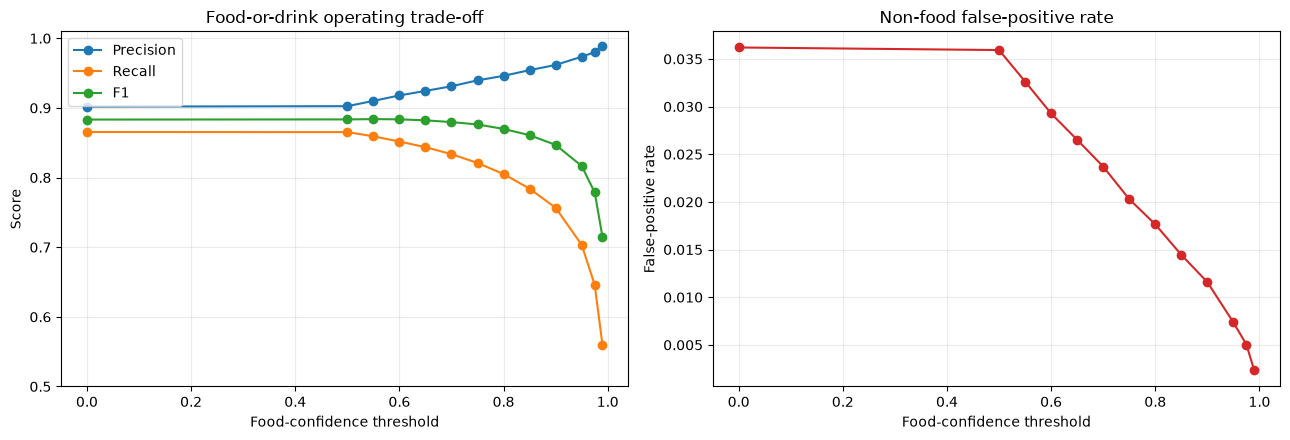

In [6]:
import matplotlib.pyplot as plt


figure, axes = plt.subplots(
    1,
    2,
    figsize=(13, 4.5),
)

axes[0].plot(
    threshold_results["threshold"],
    threshold_results[
        "pooled_food_precision"
    ],
    marker="o",
    label="Precision",
)

axes[0].plot(
    threshold_results["threshold"],
    threshold_results[
        "pooled_food_recall"
    ],
    marker="o",
    label="Recall",
)

axes[0].plot(
    threshold_results["threshold"],
    threshold_results[
        "pooled_food_f1"
    ],
    marker="o",
    label="F1",
)

axes[0].set(
    xlabel="Food-confidence threshold",
    ylabel="Score",
    title="Food-or-drink operating trade-off",
    ylim=(0.5, 1.01),
)

axes[0].grid(
    alpha=0.25
)

axes[0].legend()

axes[1].plot(
    threshold_results["threshold"],
    threshold_results[
        "pooled_food_fpr"
    ],
    marker="o",
    color="tab:red",
)

axes[1].set(
    xlabel="Food-confidence threshold",
    ylabel="False-positive rate",
    title="Non-food false-positive rate",
)

axes[1].grid(
    alpha=0.25
)

plt.tight_layout()
plt.show()

### Threshold-sweep findings

The confidence gate produces the expected precision–recall trade-off.

A threshold of 0.60 slightly improves pooled macro-F1 while increasing food
precision from 0.9019 to 0.9179 and retaining recall 0.8518. Higher thresholds
progressively reduce false positives: threshold 0.85 reaches precision 0.9543
and reduces the false-positive rate from 0.0362 to 0.0144, while retaining
recall 0.7841.

Threshold 0.95 is substantially more conservative, reaching precision 0.9735
and false-positive rate 0.0074, but food recall falls to 0.7034. Threshold 0.99
reduces recall to 0.5595 and is unlikely to be useful unless false positives are
extremely costly.

These precision values reflect the controlled dataset, where 27.8% of windows
are food-or-drink. They cannot be transferred directly to an environment where
food activity is much rarer.

## 4. Sensitivity to food prevalence

Expected food precision depends on both classifier behavior and the prevalence
of true food windows. The following calculation applies Bayes' rule using the
observed food recall and non-food false-positive rate:

$$
P(\mathrm{food}\mid\mathrm{positive}) =
\frac{\mathrm{recall}\times\mathrm{prevalence}}
{\mathrm{recall}\times\mathrm{prevalence}
+\mathrm{FPR}\times(1-\mathrm{prevalence})}
$$

The 1%, 5%, 10%, and 20% scenarios are illustrative operating conditions, not
estimates of actual daily food prevalence. The calculation also assumes that
recall and false-positive rate remain stable when prevalence changes, which may
not hold under real-world distribution shift.

In [7]:
observed_food_prevalence = (
    policy_data["y_true"]
    .eq("food_or_drink")
    .mean()
)

PREVALENCE_SCENARIOS = {
    "1%": 0.01,
    "5%": 0.05,
    "10%": 0.10,
    "20%": 0.20,
    "observed_27.8%": (
        observed_food_prevalence
    ),
}


def expected_precision_at_prevalence(
    recall,
    false_positive_rate,
    prevalence,
):
    numerator = (
        recall
        * prevalence
    )

    denominator = (
        numerator
        + false_positive_rate
        * (1.0 - prevalence)
    )

    return (
        numerator / denominator
        if denominator > 0
        else 0.0
    )


prevalence_rows = []

for result in (
    threshold_results.itertuples(
        index=False
    )
):
    for scenario, prevalence in (
        PREVALENCE_SCENARIOS.items()
    ):
        prevalence_rows.append({
            "threshold": float(
                result.threshold
            ),
            "scenario": scenario,
            "prevalence": prevalence,
            "expected_food_precision": (
                expected_precision_at_prevalence(
                    recall=(
                        result.pooled_food_recall
                    ),
                    false_positive_rate=(
                        result.pooled_food_fpr
                    ),
                    prevalence=prevalence,
                )
            ),
        })

prevalence_results = pd.DataFrame(
    prevalence_rows
)

prevalence_precision_table = (
    prevalence_results
    .pivot(
        index="threshold",
        columns="scenario",
        values="expected_food_precision",
    )
    .reindex(
        columns=list(
            PREVALENCE_SCENARIOS
        )
    )
)

display(
    prevalence_precision_table.round(4)
)

scenario,1%,5%,10%,20%,observed_27.8%
threshold,,,,,
0.000,0.1945,0.5572,0.7265,0.8567,0.9019
0.500,0.1957,0.5590,0.7280,0.8576,0.9025
0.550,0.2101,0.5809,0.7453,0.8681,0.9101
0.600,0.2271,0.6050,0.7638,0.8791,0.9179
0.650,0.2432,0.6261,0.7795,0.8883,0.9244
0.700,0.2621,0.6493,0.7963,0.8979,0.9311
0.750,0.2901,0.6804,0.8180,0.9100,0.9396
0.800,0.3155,0.7061,0.8353,0.9194,0.9461
0.850,0.3541,0.7407,0.8578,0.9314,0.9543


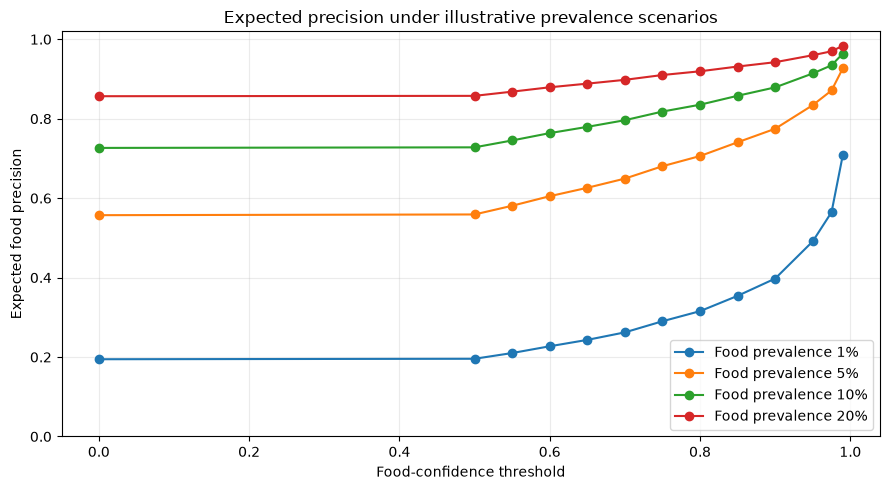

In [8]:
figure, axis = plt.subplots(
    figsize=(9, 5)
)

for scenario in [
    "1%",
    "5%",
    "10%",
    "20%",
]:
    scenario_data = (
        prevalence_results[
            prevalence_results[
                "scenario"
            ] == scenario
        ]
    )

    axis.plot(
        scenario_data["threshold"],
        scenario_data[
            "expected_food_precision"
        ],
        marker="o",
        label=(
            f"Food prevalence {scenario}"
        ),
    )

axis.set(
    xlabel="Food-confidence threshold",
    ylabel="Expected food precision",
    title=(
        "Expected precision under "
        "illustrative prevalence scenarios"
    ),
    ylim=(0.0, 1.02),
)

axis.grid(alpha=0.25)
axis.legend()

plt.tight_layout()
plt.show()

### Prevalence-sensitivity findings

The controlled-data precision substantially overstates likely performance when
food windows are uncommon.

At an illustrative 5% food prevalence, expected food precision falls from
0.9019 to 0.5572 under the reference policy. Thresholds 0.85 and 0.95 improve
this estimate to 0.7407 and 0.8342, respectively, but threshold 0.95 retains
only 0.7034 window recall.

At 1% prevalence, no moderate single-window threshold is sufficient. Even
threshold 0.95 produces expected precision below 0.50. Threshold 0.99 reaches
higher precision but reduces window recall to 0.5595.

This demonstrates that a production prompt should not depend on one
five-second classification. The next analysis evaluates whether persistent
evidence across consecutive windows can suppress isolated false positives while
still detecting food-activity recordings.

## 5. Consecutive-window confirmation

Windows are ordered within each subject/activity recording by their canonical
window position. A candidate event is a run of food-positive windows with
consecutive positions.

The analysis compares confirmation requirements of one through four consecutive
windows, corresponding to 5–20 seconds of continuous evidence. A gap in window
position resets the run.

Because WISDM consists of controlled activity blocks rather than natural daily
timelines, the results are controlled recording-level diagnostics. They do not
estimate real-world meals, prompts per day, or event precision.

In [9]:
TEMPORAL_THRESHOLDS = np.asarray([
    0.0,
    0.60,
    0.75,
    0.85,
    0.90,
    0.95,
])

CONSECUTIVE_WINDOWS = [
    1,
    2,
    3,
    4,
]


def build_food_run_tables(
    data,
    predictions,
):
    sequence_data = data[
        [
            "user_id",
            "activity_code",
            "window_position",
            "outer_fold",
            "y_true",
        ]
    ].copy()

    sequence_data[
        "candidate_food"
    ] = (
        np.asarray(predictions)
        == "food_or_drink"
    )

    sequence_data = (
        sequence_data
        .sort_values(
            [
                "user_id",
                "activity_code",
                "window_position",
            ]
        )
        .reset_index(drop=True)
    )

    recording_rows = []
    run_rows = []

    for (
        user_id,
        activity_code,
    ), recording in (
        sequence_data.groupby(
            [
                "user_id",
                "activity_code",
            ],
            sort=True,
        )
    ):
        true_labels = (
            recording[
                "y_true"
            ].unique()
        )

        folds = (
            recording[
                "outer_fold"
            ].unique()
        )

        assert len(true_labels) == 1
        assert len(folds) == 1

        positions = recording[
            "window_position"
        ].to_numpy()

        positive = recording[
            "candidate_food"
        ].to_numpy()

        continuation = np.zeros(
            len(recording),
            dtype=bool,
        )

        if len(recording) > 1:
            continuation[1:] = (
                positive[1:]
                & positive[:-1]
                & (
                    np.diff(positions)
                    == 1
                )
            )

        run_starts = (
            positive
            & ~continuation
        )

        run_ids = np.cumsum(
            run_starts
        )

        if positive.any():
            run_lengths = (
                pd.Series(
                    run_ids[positive]
                )
                .value_counts(
                    sort=False
                )
                .sort_index()
            )
        else:
            run_lengths = (
                pd.Series(dtype=int)
            )

        recording_rows.append({
            "user_id": int(user_id),
            "activity_code": str(
                activity_code
            ),
            "outer_fold": int(
                folds[0]
            ),
            "y_true": str(
                true_labels[0]
            ),
            "windows": len(recording),
            "maximum_food_run": (
                int(
                    run_lengths.max()
                )
                if len(run_lengths)
                else 0
            ),
        })

        for run_number, run_length in (
            enumerate(
                run_lengths,
                start=1,
            )
        ):
            run_rows.append({
                "user_id": int(user_id),
                "activity_code": str(
                    activity_code
                ),
                "outer_fold": int(
                    folds[0]
                ),
                "y_true": str(
                    true_labels[0]
                ),
                "run_number": run_number,
                "run_length": int(
                    run_length
                ),
            })

    return (
        pd.DataFrame(recording_rows),
        pd.DataFrame(run_rows),
    )

In [10]:
recording_reference = (
    policy_data[
        [
            "user_id",
            "activity_code",
            "y_true",
            "window_position",
        ]
    ]
    .groupby(
        [
            "user_id",
            "activity_code",
            "y_true",
        ],
        observed=True,
    )
    .agg(
        windows=(
            "window_position",
            "size",
        ),
        first_position=(
            "window_position",
            "min",
        ),
        last_position=(
            "window_position",
            "max",
        ),
    )
    .reset_index()
)

assert not recording_reference[
    [
        "user_id",
        "activity_code",
    ]
].duplicated().any()

recording_support = (
    recording_reference
    .groupby(
        "y_true",
        observed=True,
    )
    .agg(
        recordings=(
            "activity_code",
            "size",
        ),
        total_windows=(
            "windows",
            "sum",
        ),
        minimum_windows=(
            "windows",
            "min",
        ),
        median_windows=(
            "windows",
            "median",
        ),
        maximum_windows=(
            "windows",
            "max",
        ),
    )
    .reindex(
        BUSINESS_LABELS
    )
)

display(
    recording_support
)

,recordings,total_windows,minimum_windows,median_windows,maximum_windows
y_true,,,,,
physical_activity,242,8470,35,35.0,35
food_or_drink,203,7105,35,35.0,35
other_daily_activity,286,10010,35,35.0,35


In [11]:
event_policy_rows = []

for threshold in (
    TEMPORAL_THRESHOLDS
):
    threshold_predictions = (
        apply_food_confidence_gate(
            policy_data,
            threshold=threshold,
        )
    )

    recording_table, run_table = (
        build_food_run_tables(
            policy_data,
            threshold_predictions,
        )
    )

    true_food_recordings = (
        recording_table[
            recording_table[
                "y_true"
            ] == "food_or_drink"
        ]
    )

    non_food_recordings = (
        recording_table[
            recording_table[
                "y_true"
            ] != "food_or_drink"
        ]
    )

    non_food_hours = (
        non_food_recordings[
            "windows"
        ].sum()
        * 5.0
        / 3600.0
    )

    for required_windows in (
        CONSECUTIVE_WINDOWS
    ):
        qualifying_runs = (
            run_table[
                run_table[
                    "run_length"
                ] >= required_windows
            ]
        )

        true_runs = (
            qualifying_runs[
                qualifying_runs[
                    "y_true"
                ] == "food_or_drink"
            ]
        )

        false_runs = (
            qualifying_runs[
                qualifying_runs[
                    "y_true"
                ] != "food_or_drink"
            ]
        )

        detected_food_recordings = (
            true_runs[
                [
                    "user_id",
                    "activity_code",
                ]
            ]
            .drop_duplicates()
            .shape[0]
        )

        alerted_non_food_recordings = (
            false_runs[
                [
                    "user_id",
                    "activity_code",
                ]
            ]
            .drop_duplicates()
            .shape[0]
        )

        event_policy_rows.append({
            "threshold": float(
                threshold
            ),
            "consecutive_windows": int(
                required_windows
            ),
            "confirmation_seconds": int(
                required_windows * 5
            ),
            "food_recording_detection_rate": (
                detected_food_recordings
                / len(
                    true_food_recordings
                )
            ),
            "non_food_recording_alert_rate": (
                alerted_non_food_recordings
                / len(
                    non_food_recordings
                )
            ),
            "controlled_false_runs_per_non_food_hour": (
                len(false_runs)
                / non_food_hours
            ),
            "detected_food_recordings": int(
                detected_food_recordings
            ),
            "alerted_non_food_recordings": int(
                alerted_non_food_recordings
            ),
            "true_qualifying_runs": int(
                len(true_runs)
            ),
            "false_qualifying_runs": int(
                len(false_runs)
            ),
        })

event_policy_results = pd.DataFrame(
    event_policy_rows
)

display(
    event_policy_results.round(4)
)

,threshold,consecutive_windows,confirmation_seconds,food_recording_detection_rate,non_food_recording_alert_rate,controlled_false_runs_per_non_food_hour,detected_food_recordings,alerted_non_food_recordings,true_qualifying_runs,false_qualifying_runs
0,0.00,1,5,0.9803,0.2348,13.2857,199,124,565,341
1,0.00,2,10,0.9557,0.0928,4.0130,194,49,460,103
2,0.00,3,15,0.9557,0.0663,2.3377,194,35,368,60
3,0.00,4,20,0.9310,0.0473,1.4026,189,25,328,36
4,0.60,1,5,0.9704,0.2008,10.7532,197,106,596,276
5,0.60,2,10,0.9557,0.0777,3.2338,194,41,478,83
6,0.60,3,15,0.9458,0.0587,1.9091,192,31,380,49
7,0.60,4,20,0.9261,0.0398,1.0909,188,21,333,28
8,0.75,1,5,0.9704,0.1648,8.2208,197,87,686,211
9,0.75,2,10,0.9507,0.0587,2.0649,193,31,510,53


### Temporal-confirmation findings

The development artifact contains 731 controlled recordings, each with exactly
35 paired windows or 175 seconds of sensor data. This uniform structure makes
the comparison straightforward, but it is substantially simpler than a natural
daily timeline.

Temporal confirmation strongly suppresses isolated errors. Under the reference
threshold, requiring four consecutive food-positive windows reduces the
non-food recording alert rate from 0.2348 to 0.0473 while retaining food-
recording detection of 0.9310.

Several policies form a useful shortlist:

- threshold 0.90 with two windows: shorter 10-second confirmation and higher
  detection, but more false runs;
- threshold 0.95 with two windows: conservative confidence with 10-second
  confirmation;
- threshold 0.85 with three windows: moderate confidence with 15-second
  confirmation;
- threshold 0.75 with four windows: 20-second confirmation and the lowest false-
  run rate among candidates retaining at least 90% pooled recording detection.

The threshold-0.95/two-window and threshold-0.75/four-window policies have the
same pooled food-recording detection and non-food recording alert rates.
However, the former responds faster while the latter produces fewer fragmented
false runs. Fold-level behavior is examined before choosing between them.

## 6. Fold robustness of candidate policies

In [12]:
POLICY_SHORTLIST = pd.DataFrame([
    {
        "policy": "threshold_0.90__2_windows",
        "threshold": 0.90,
        "consecutive_windows": 2,
    },
    {
        "policy": "threshold_0.95__2_windows",
        "threshold": 0.95,
        "consecutive_windows": 2,
    },
    {
        "policy": "threshold_0.85__3_windows",
        "threshold": 0.85,
        "consecutive_windows": 3,
    },
    {
        "policy": "threshold_0.75__4_windows",
        "threshold": 0.75,
        "consecutive_windows": 4,
    },
])

shortlist_fold_rows = []

for candidate in (
    POLICY_SHORTLIST.itertuples(
        index=False
    )
):
    candidate_predictions = (
        apply_food_confidence_gate(
            policy_data,
            threshold=(
                candidate.threshold
            ),
        )
    )

    candidate_recordings, candidate_runs = (
        build_food_run_tables(
            policy_data,
            candidate_predictions,
        )
    )

    for outer_fold in sorted(
        candidate_recordings[
            "outer_fold"
        ].unique()
    ):
        fold_recordings = (
            candidate_recordings[
                candidate_recordings[
                    "outer_fold"
                ] == outer_fold
            ]
        )

        fold_runs = (
            candidate_runs[
                candidate_runs[
                    "outer_fold"
                ] == outer_fold
            ]
        )

        qualifying_runs = (
            fold_runs[
                fold_runs[
                    "run_length"
                ] >= (
                    candidate
                    .consecutive_windows
                )
            ]
        )

        food_recordings = (
            fold_recordings[
                fold_recordings[
                    "y_true"
                ] == "food_or_drink"
            ]
        )

        non_food_recordings = (
            fold_recordings[
                fold_recordings[
                    "y_true"
                ] != "food_or_drink"
            ]
        )

        true_runs = (
            qualifying_runs[
                qualifying_runs[
                    "y_true"
                ] == "food_or_drink"
            ]
        )

        false_runs = (
            qualifying_runs[
                qualifying_runs[
                    "y_true"
                ] != "food_or_drink"
            ]
        )

        detected_food_recordings = (
            true_runs[
                [
                    "user_id",
                    "activity_code",
                ]
            ]
            .drop_duplicates()
            .shape[0]
        )

        alerted_non_food_recordings = (
            false_runs[
                [
                    "user_id",
                    "activity_code",
                ]
            ]
            .drop_duplicates()
            .shape[0]
        )

        non_food_hours = (
            non_food_recordings[
                "windows"
            ].sum()
            * 5.0
            / 3600.0
        )

        shortlist_fold_rows.append({
            "policy": candidate.policy,
            "fold": int(outer_fold),
            "food_recording_detection_rate": (
                detected_food_recordings
                / len(food_recordings)
            ),
            "non_food_recording_alert_rate": (
                alerted_non_food_recordings
                / len(
                    non_food_recordings
                )
            ),
            "controlled_false_runs_per_non_food_hour": (
                len(false_runs)
                / non_food_hours
            ),
        })

shortlist_fold_results = pd.DataFrame(
    shortlist_fold_rows
)

display(
    shortlist_fold_results.round(4)
)

,policy,fold,food_recording_detection_rate,non_food_recording_alert_rate,controlled_false_runs_per_non_food_hour
0,threshold_0.90__2_windows,1,0.9778,0.0085,0.1758
1,threshold_0.90__2_windows,2,0.8974,0.0485,1.3981
2,threshold_0.90__2_windows,3,0.9500,0.0490,1.6134
3,threshold_0.90__2_windows,4,0.8205,0.0485,1.1983
4,threshold_0.90__2_windows,5,0.9250,0.0291,0.9986
5,threshold_0.95__2_windows,1,0.9778,0.0000,0.0000
6,threshold_0.95__2_windows,2,0.8974,0.0291,1.1983
7,threshold_0.95__2_windows,3,0.9500,0.0392,1.4118
8,threshold_0.95__2_windows,4,0.8205,0.0388,1.1983
9,threshold_0.95__2_windows,5,0.8500,0.0194,0.3994


In [13]:
shortlist_summary = (
    shortlist_fold_results
    .groupby(
        "policy",
        sort=False,
    )
    .agg(
        mean_food_recording_detection=(
            "food_recording_detection_rate",
            "mean",
        ),
        minimum_fold_food_detection=(
            "food_recording_detection_rate",
            "min",
        ),
        mean_non_food_recording_alert_rate=(
            "non_food_recording_alert_rate",
            "mean",
        ),
        maximum_fold_non_food_alert_rate=(
            "non_food_recording_alert_rate",
            "max",
        ),
        mean_false_runs_per_non_food_hour=(
            "controlled_false_runs_per_non_food_hour",
            "mean",
        ),
        maximum_fold_false_runs_per_non_food_hour=(
            "controlled_false_runs_per_non_food_hour",
            "max",
        ),
    )
    .reset_index()
)

display(
    shortlist_summary.round(4)
)

,policy,mean_food_recording_detection,minimum_fold_food_detection,mean_non_food_recording_alert_rate,maximum_fold_non_food_alert_rate,mean_false_runs_per_non_food_hour,maximum_fold_false_runs_per_non_food_hour
0,threshold_0.90__2_windows,0.9141,0.8205,0.0368,0.0490,1.0769,1.6134
1,threshold_0.95__2_windows,0.8991,0.8205,0.0253,0.0392,0.8416,1.4118
2,threshold_0.85__3_windows,0.9000,0.8718,0.0290,0.0490,0.7961,1.1983
3,threshold_0.75__4_windows,0.9005,0.8718,0.0251,0.0388,0.6355,1.1983


### Candidate-policy findings

Threshold 0.75 with four consecutive food-positive windows is selected as the
development business policy.

It retains mean fold food-recording detection of 0.9005, with a minimum fold
value of 0.8718. Its mean non-food recording alert rate is 0.0251 and remains
below 0.04 in every fold. It also produces the lowest mean and worst-fold false-
run rates among the shortlisted policies.

The selected policy requires 20 seconds of continuous evidence. This favors
false-alert control over response speed. It may be appropriate for sustained
eating behavior but could miss brief drinking events or food gestures separated
by non-food predictions. The final test will apply this rule without alteration,
but naturalistic data would still be required to validate its real-world
latency and notification behavior.

## 7. Selected-policy diagnostics

Before freezing the policy, its performance is examined across individual
subjects and original activities. This checks whether the pooled recording
result hides concentrated failures or a particular source of false events.

In [14]:
SELECTED_FOOD_THRESHOLD = 0.75
SELECTED_CONSECUTIVE_WINDOWS = 4
SELECTED_CONFIRMATION_SECONDS = (
    SELECTED_CONSECUTIVE_WINDOWS
    * 5
)

selected_window_predictions = (
    apply_food_confidence_gate(
        policy_data,
        threshold=(
            SELECTED_FOOD_THRESHOLD
        ),
    )
)

selected_window_metrics = (
    calculate_policy_metrics(
        policy_data["y_true"],
        selected_window_predictions,
    )
)

selected_recordings, selected_runs = (
    build_food_run_tables(
        policy_data,
        selected_window_predictions,
    )
)

selected_qualifying_runs = (
    selected_runs[
        selected_runs[
            "run_length"
        ] >= (
            SELECTED_CONSECUTIVE_WINDOWS
        )
    ]
)

selected_event_counts = (
    selected_qualifying_runs
    .groupby(
        [
            "user_id",
            "activity_code",
        ],
        observed=True,
    )
    .size()
    .rename(
        "qualifying_event_count"
    )
    .reset_index()
)

selected_recordings = (
    selected_recordings
    .merge(
        selected_event_counts,
        on=[
            "user_id",
            "activity_code",
        ],
        how="left",
        validate="one_to_one",
    )
)

selected_recordings[
    "qualifying_event_count"
] = (
    selected_recordings[
        "qualifying_event_count"
    ]
    .fillna(0)
    .astype(int)
)

selected_recordings[
    "event_detected"
] = (
    selected_recordings[
        "qualifying_event_count"
    ] > 0
)

selected_food_recordings = (
    selected_recordings[
        selected_recordings[
            "y_true"
        ] == "food_or_drink"
    ]
)

selected_non_food_recordings = (
    selected_recordings[
        selected_recordings[
            "y_true"
        ] != "food_or_drink"
    ]
)

selected_non_food_hours = (
    selected_non_food_recordings[
        "windows"
    ].sum()
    * 5.0
    / 3600.0
)

selected_event_summary = pd.Series({
    "food_threshold": (
        SELECTED_FOOD_THRESHOLD
    ),
    "consecutive_windows": (
        SELECTED_CONSECUTIVE_WINDOWS
    ),
    "confirmation_seconds": (
        SELECTED_CONFIRMATION_SECONDS
    ),
    "window_food_precision": (
        selected_window_metrics[
            "food_precision"
        ]
    ),
    "window_food_recall": (
        selected_window_metrics[
            "food_recall"
        ]
    ),
    "window_food_false_positive_rate": (
        selected_window_metrics[
            "food_false_positive_rate"
        ]
    ),
    "food_recording_detection_rate": (
        selected_food_recordings[
            "event_detected"
        ].mean()
    ),
    "non_food_recording_alert_rate": (
        selected_non_food_recordings[
            "event_detected"
        ].mean()
    ),
    "controlled_false_runs_per_non_food_hour": (
        selected_non_food_recordings[
            "qualifying_event_count"
        ].sum()
        / selected_non_food_hours
    ),
})

display(
    selected_event_summary
    .to_frame(
        name="development_value"
    )
    .round(4)
)

,development_value
food_threshold,0.7500
consecutive_windows,4.0000
confirmation_seconds,20.0000
window_food_precision,0.9396
window_food_recall,0.8210
window_food_false_positive_rate,0.0203
food_recording_detection_rate,0.9015
non_food_recording_alert_rate,0.0246
controlled_false_runs_per_non_food_hour,0.6234


In [15]:
subject_event_rows = []

for user_id, subject_data in (
    selected_recordings.groupby(
        "user_id",
        sort=True,
    )
):
    food_data = (
        subject_data[
            subject_data[
                "y_true"
            ] == "food_or_drink"
        ]
    )

    non_food_data = (
        subject_data[
            subject_data[
                "y_true"
            ] != "food_or_drink"
        ]
    )

    subject_event_rows.append({
        "user_id": int(user_id),
        "fold": int(
            subject_data[
                "outer_fold"
            ].iloc[0]
        ),
        "food_recordings": len(
            food_data
        ),
        "detected_food_recordings": int(
            food_data[
                "event_detected"
            ].sum()
        ),
        "food_recording_detection_rate": (
            food_data[
                "event_detected"
            ].mean()
        ),
        "non_food_recordings": len(
            non_food_data
        ),
        "alerted_non_food_recordings": int(
            non_food_data[
                "event_detected"
            ].sum()
        ),
        "non_food_recording_alert_rate": (
            non_food_data[
                "event_detected"
            ].mean()
        ),
        "false_qualifying_runs": int(
            non_food_data[
                "qualifying_event_count"
            ].sum()
        ),
    })

subject_event_metrics = pd.DataFrame(
    subject_event_rows
)

display(
    subject_event_metrics[
        [
            "food_recording_detection_rate",
            "non_food_recording_alert_rate",
            "false_qualifying_runs",
        ]
    ]
    .describe(
        percentiles=[
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
        ]
    )
    .T
    .round(4)
)

display(
    subject_event_metrics
    .sort_values(
        [
            "food_recording_detection_rate",
            "non_food_recording_alert_rate",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .head(10)
    .round(4)
)

,count,mean,std,min,10%,25%,50%,75%,90%,max
food_recording_detection_rate,41.0,0.8939,0.2335,0.0,0.6,1.0,1.0,1.0000,1.0000,1.0000
non_food_recording_alert_rate,41.0,0.0245,0.0439,0.0,0.0,0.0,0.0,0.0769,0.0769,0.1538
false_qualifying_runs,41.0,0.3902,0.7028,0.0,0.0,0.0,0.0,1.0000,2.0000,2.0000


,user_id,fold,food_recordings,detected_food_recordings,food_recording_detection_rate,non_food_recordings,alerted_non_food_recordings,non_food_recording_alert_rate,false_qualifying_runs
32,1637,2,4,0,0.00,12,0,0.0000,0
33,1638,4,4,1,0.25,12,0,0.0000,0
24,1628,1,5,2,0.40,13,0,0.0000,0
37,1647,4,5,3,0.60,13,1,0.0769,2
28,1633,5,5,3,0.60,13,0,0.0000,0
34,1642,3,5,3,0.60,11,0,0.0000,0
38,1648,5,5,3,0.60,13,0,0.0000,0
35,1644,3,5,4,0.80,13,1,0.0769,1
7,1609,5,5,4,0.80,13,0,0.0000,0
9,1611,2,5,5,1.00,13,2,0.1538,2


In [16]:
ACTIVITY_NAME_BY_CODE = (
    mapping_record[
        "activity_code_to_name"
    ]
)

activity_event_metrics = (
    selected_recordings
    .groupby(
        [
            "activity_code",
            "y_true",
        ],
        observed=True,
    )
    .agg(
        recordings=(
            "user_id",
            "size",
        ),
        recording_detection_or_alert_rate=(
            "event_detected",
            "mean",
        ),
        qualifying_runs=(
            "qualifying_event_count",
            "sum",
        ),
    )
    .reset_index()
)

activity_event_metrics.insert(
    1,
    "activity_name",
    activity_event_metrics[
        "activity_code"
    ].map(
        ACTIVITY_NAME_BY_CODE
    ),
)

display(
    activity_event_metrics[
        activity_event_metrics[
            "y_true"
        ] == "food_or_drink"
    ].round(4)
)

display(
    activity_event_metrics[
        (
            activity_event_metrics[
                "y_true"
            ] != "food_or_drink"
        )
        & (
            activity_event_metrics[
                "qualifying_runs"
            ] > 0
        )
    ].round(4)
)

,activity_code,activity_name,y_true,recordings,recording_detection_or_alert_rate,qualifying_runs
7,H,Eating Soup,food_or_drink,40,0.9750,66
8,I,Eating Chips,food_or_drink,41,0.8780,73
9,J,Eating Pasta,food_or_drink,40,0.8500,57
10,K,Drinking from Cup,food_or_drink,41,0.9268,68
11,L,Eating Sandwich,food_or_drink,41,0.8780,71


,activity_code,activity_name,y_true,recordings,recording_detection_or_alert_rate,qualifying_runs
3,D,Sitting,other_daily_activity,41,0.1707,9
4,E,Standing,other_daily_activity,41,0.0732,3
15,Q,Writing,other_daily_activity,41,0.0732,4


### Food-event-policy findings

The selected policy reaches pooled food-recording detection 0.9015 while
alerting 0.0246 of controlled non-food recordings. Its window-level food
precision is 0.9396, with recall 0.8210 and a non-food false-positive rate of
0.0203.

Most subjects perform well: the median subject has all available food
recordings detected and no non-food recording alerted. Nevertheless, failures
remain strongly subject-dependent. Subject 1637 has no food recording detected,
subject 1638 has one of four detected, and subject 1628 has two of five
detected. These are not failures that temporal confirmation can repair because
the underlying classifier provides insufficient food evidence.

Eating Soup has the highest recording detection rate at 0.9750. Drinking from
Cup reaches 0.9268 in the controlled repeated-activity recordings, while Eating
Pasta is lowest at 0.8500.

All 16 false qualifying runs come from three other-daily activities: Sitting
produces nine, Writing four, and Standing three. No physical-activity recording
produces a qualifying food run.

## 8. Physical-activity accounting policy

Food-or-drink detection required a conservative event policy because a false
positive could trigger an intrusive prompt. Physical activity has a different
product action: its windows contribute to accumulated movement evidence rather
than immediately notifying the user.

The selected food-confidence gate still produces one final class for every
window. The proposed physical policy is therefore:

- every final `physical_activity` window contributes five seconds of movement
  evidence;
- no additional physical-confidence threshold is applied;
- physical windows do not need to be consecutive;
- the accumulated duration is not interpreted as exercise-session duration,
  calories, or validated real-world active minutes.

A separate physical threshold sweep is not performed because no concrete cost
ratio or alerting action has been defined for movement tracking. Introducing
another tuned threshold without such a decision objective would add arbitrary
model selection.

The following diagnostics evaluate physical precision, recall, false-positive
rate, subject variability, and accumulated-duration error under this rule.

In [18]:
def calculate_physical_metrics(
    y_true,
    y_pred,
):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    true_physical = (
        y_true == "physical_activity"
    )

    predicted_physical = (
        y_pred == "physical_activity"
    )

    true_positive = int(
        (
            true_physical
            & predicted_physical
        ).sum()
    )

    false_positive = int(
        (
            ~true_physical
            & predicted_physical
        ).sum()
    )

    false_negative = int(
        (
            true_physical
            & ~predicted_physical
        ).sum()
    )

    true_negative = int(
        (
            ~true_physical
            & ~predicted_physical
        ).sum()
    )

    precision = (
        true_positive
        / (
            true_positive
            + false_positive
        )
        if (
            true_positive
            + false_positive
        )
        else 0.0
    )

    recall = (
        true_positive
        / (
            true_positive
            + false_negative
        )
    )

    false_positive_rate = (
        false_positive
        / (
            false_positive
            + true_negative
        )
    )

    f1 = (
        2.0
        * precision
        * recall
        / (
            precision
            + recall
        )
        if (
            precision
            + recall
        )
        else 0.0
    )

    return {
        "physical_precision": precision,
        "physical_recall": recall,
        "physical_f1": f1,
        "physical_false_positive_rate": (
            false_positive_rate
        ),
        "physical_true_positives": (
            true_positive
        ),
        "physical_false_positives": (
            false_positive
        ),
        "physical_false_negatives": (
            false_negative
        ),
    }


selected_physical_metrics = (
    calculate_physical_metrics(
        policy_data["y_true"],
        selected_window_predictions,
    )
)

physical_fold_rows = []

for outer_fold, fold_data in (
    policy_data.assign(
        selected_window_prediction=(
            selected_window_predictions
        )
    )
    .groupby(
        "outer_fold",
        sort=True,
    )
):
    physical_fold_rows.append({
        "fold": int(outer_fold),
        **calculate_physical_metrics(
            fold_data["y_true"],
            fold_data[
                "selected_window_prediction"
            ],
        ),
    })

physical_fold_metrics = pd.DataFrame(
    physical_fold_rows
)

display(
    pd.Series(
        selected_physical_metrics,
        name="pooled_value",
    )
    .to_frame()
    .round(4)
)

display(
    physical_fold_metrics[
        [
            "fold",
            "physical_precision",
            "physical_recall",
            "physical_f1",
            "physical_false_positive_rate",
        ]
    ].round(4)
)

,pooled_value
physical_precision,0.9798
physical_recall,0.9569
physical_f1,0.9682
physical_false_positive_rate,0.0098
physical_true_positives,8105.0000
physical_false_positives,167.0000
physical_false_negatives,365.0000


,fold,physical_precision,physical_recall,physical_f1,physical_false_positive_rate
0,1,0.9853,0.9915,0.9884,0.0074
1,2,0.9603,0.9271,0.9434,0.0189
2,3,0.9801,0.9605,0.9702,0.0096
3,4,0.9881,0.9568,0.9722,0.0057
4,5,0.9841,0.9435,0.9634,0.0074


In [19]:
physical_policy_data = (
    policy_data.assign(
        selected_window_prediction=(
            selected_window_predictions
        ),
        true_physical_window=lambda frame: (
            frame["y_true"]
            == "physical_activity"
        ),
        predicted_physical_window=lambda frame: (
            frame[
                "selected_window_prediction"
            ]
            == "physical_activity"
        ),
    )
)

physical_subject_rows = []

for user_id, subject_data in (
    physical_policy_data.groupby(
        "user_id",
        sort=True,
    )
):
    subject_metrics = (
        calculate_physical_metrics(
            subject_data["y_true"],
            subject_data[
                "selected_window_prediction"
            ],
        )
    )

    actual_physical_seconds = int(
        subject_data[
            "true_physical_window"
        ].sum()
        * 5
    )

    predicted_physical_seconds = int(
        subject_data[
            "predicted_physical_window"
        ].sum()
        * 5
    )

    physical_subject_rows.append({
        "user_id": int(user_id),
        "fold": int(
            subject_data[
                "outer_fold"
            ].iloc[0]
        ),
        **subject_metrics,
        "actual_physical_seconds": (
            actual_physical_seconds
        ),
        "predicted_physical_seconds": (
            predicted_physical_seconds
        ),
        "duration_error_seconds": (
            predicted_physical_seconds
            - actual_physical_seconds
        ),
        "absolute_duration_error_seconds": abs(
            predicted_physical_seconds
            - actual_physical_seconds
        ),
    })

physical_subject_metrics = pd.DataFrame(
    physical_subject_rows
)

physical_subject_metrics[
    "relative_duration_error"
] = (
    physical_subject_metrics[
        "duration_error_seconds"
    ]
    / physical_subject_metrics[
        "actual_physical_seconds"
    ]
)

pooled_actual_physical_seconds = int(
    physical_policy_data[
        "true_physical_window"
    ].sum()
    * 5
)

pooled_predicted_physical_seconds = int(
    physical_policy_data[
        "predicted_physical_window"
    ].sum()
    * 5
)

physical_duration_summary = pd.Series({
    "actual_physical_minutes": (
        pooled_actual_physical_seconds
        / 60.0
    ),
    "predicted_physical_minutes": (
        pooled_predicted_physical_seconds
        / 60.0
    ),
    "duration_error_minutes": (
        (
            pooled_predicted_physical_seconds
            - pooled_actual_physical_seconds
        )
        / 60.0
    ),
    "relative_duration_error": (
        (
            pooled_predicted_physical_seconds
            - pooled_actual_physical_seconds
        )
        / pooled_actual_physical_seconds
    ),
})

display(
    physical_duration_summary
    .to_frame(
        name="development_value"
    )
    .round(4)
)

display(
    physical_subject_metrics[
        [
            "physical_precision",
            "physical_recall",
            "physical_f1",
            "physical_false_positive_rate",
            "duration_error_seconds",
            "absolute_duration_error_seconds",
            "relative_duration_error",
        ]
    ]
    .describe(
        percentiles=[
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
        ]
    )
    .T
    .round(4)
)

display(
    physical_subject_metrics
    .nlargest(
        8,
        "absolute_duration_error_seconds",
    )[
        [
            "user_id",
            "fold",
            "physical_precision",
            "physical_recall",
            "physical_f1",
            "actual_physical_seconds",
            "predicted_physical_seconds",
            "duration_error_seconds",
            "relative_duration_error",
        ]
    ]
    .round(4)
)

,development_value
actual_physical_minutes,705.8333
predicted_physical_minutes,689.3333
duration_error_minutes,-16.5000
relative_duration_error,-0.0234


,count,mean,std,min,10%,25%,50%,75%,90%,max
physical_precision,41.0,0.9793,0.0300,0.8581,0.9479,0.9807,0.9904,0.9951,1.0000,1.0000
physical_recall,41.0,0.9538,0.0899,0.5200,0.8952,0.9667,0.9857,1.0000,1.0000,1.0000
physical_f1,41.0,0.9641,0.0603,0.6716,0.9307,0.9691,0.9835,0.9929,0.9976,1.0000
physical_false_positive_rate,41.0,0.0098,0.0142,0.0000,0.0000,0.0024,0.0048,0.0095,0.0214,0.0643
duration_error_seconds,41.0,-24.1463,80.7225,-395.0000,-95.0000,-30.0000,0.0000,10.0000,15.0000,120.0000
absolute_duration_error_seconds,41.0,42.4390,72.5786,0.0000,0.0000,5.0000,15.0000,40.0000,100.0000,395.0000
relative_duration_error,41.0,-0.0262,0.0882,-0.4514,-0.0905,-0.0286,0.0000,0.0095,0.0143,0.1143


,user_id,fold,physical_precision,physical_recall,physical_f1,actual_physical_seconds,predicted_physical_seconds,duration_error_seconds,relative_duration_error
32,1637,2,0.9479,0.5200,0.6716,875,480,-395,-0.4514
33,1638,4,1.0000,0.7771,0.8746,875,680,-195,-0.2229
28,1633,5,0.9887,0.8333,0.9044,1050,885,-165,-0.1571
6,1608,2,0.8846,0.9857,0.9324,1050,1170,120,0.1143
34,1642,3,0.8581,0.7600,0.8061,875,775,-100,-0.1143
10,1612,5,1.0000,0.9095,0.9526,1050,955,-95,-0.0905
35,1644,3,0.9895,0.9000,0.9426,1050,955,-95,-0.0905
7,1609,5,0.9691,0.8952,0.9307,1050,970,-80,-0.0762


In [20]:
physical_activity_diagnostics = (
    physical_policy_data
    .groupby(
        [
            "activity_code",
            "y_true",
        ],
        observed=True,
    )
    .agg(
        windows=(
            "array_index",
            "size",
        ),
        predicted_physical_windows=(
            "predicted_physical_window",
            "sum",
        ),
        predicted_physical_rate=(
            "predicted_physical_window",
            "mean",
        ),
    )
    .reset_index()
)

physical_activity_diagnostics.insert(
    1,
    "activity_name",
    physical_activity_diagnostics[
        "activity_code"
    ].map(
        ACTIVITY_NAME_BY_CODE
    ),
)

display(
    physical_activity_diagnostics[
        physical_activity_diagnostics[
            "y_true"
        ] == "physical_activity"
    ].round(4)
)

display(
    physical_activity_diagnostics[
        (
            physical_activity_diagnostics[
                "y_true"
            ] != "physical_activity"
        )
        & (
            physical_activity_diagnostics[
                "predicted_physical_windows"
            ] > 0
        )
    ]
    .sort_values(
        "predicted_physical_rate",
        ascending=False,
    )
    .round(4)
)

,activity_code,activity_name,y_true,windows,predicted_physical_windows,predicted_physical_rate
0,A,Walking,physical_activity,1435,1382,0.9631
1,B,Jogging,physical_activity,1400,1394,0.9957
2,C,Stairs,physical_activity,1365,1290,0.9451
12,M,Kicking Soccer Ball,physical_activity,1435,1344,0.9366
13,O,Playing Catch,physical_activity,1400,1346,0.9614
14,P,Dribbling Basketball,physical_activity,1435,1349,0.9401


,activity_code,activity_name,y_true,windows,predicted_physical_windows,predicted_physical_rate
17,S,Folding Clothes,other_daily_activity,1435,70,0.0488
16,R,Clapping,other_daily_activity,1435,31,0.0216
4,E,Standing,other_daily_activity,1435,30,0.0209
11,L,Eating Sandwich,food_or_drink,1435,23,0.0160
6,G,Brushing Teeth,other_daily_activity,1435,5,0.0035
3,D,Sitting,other_daily_activity,1435,4,0.0028
15,Q,Writing,other_daily_activity,1435,2,0.0014
7,H,Eating Soup,food_or_drink,1400,1,0.0007
10,K,Drinking from Cup,food_or_drink,1435,1,0.0007


### Physical-activity-policy findings

The simple movement-accounting rule performs strongly at the population level.
After applying the food-confidence policy, physical activity reaches pooled
precision 0.9798, recall 0.9569, and F1 0.9682. Its non-physical false-positive
rate is 0.0098.

Performance remains strong across folds: physical precision ranges from 0.9603
to 0.9881 and recall from 0.9271 to 0.9915. Jogging has the highest activity-
specific recall at 0.9957. Kicking Soccer Ball is lowest at 0.9366, followed by
Dribbling Basketball at 0.9401 and Stairs at 0.9451.

Across the controlled development data, the true physical duration is 705.8
minutes and the policy accumulates 689.3 minutes. This is an aggregate
underestimate of 16.5 minutes, or 2.34%. The median subject has no duration
error, but individual performance remains uneven.

Subject 1637 has physical recall 0.5200 and receives 395 fewer seconds of
movement evidence than observed, an underestimate of 45.1%. Subjects 1638 and
1633 are also substantially underestimated. Therefore, the small aggregate
duration error must not be interpreted as uniform accuracy across wearers.

Folding Clothes is the largest source of false physical evidence, with 4.88% of
its windows labelled physical, followed by Clapping and Standing at
approximately 2.1%. Food-or-drink activities contribute very little false
physical evidence.

The proposed rule is accepted without an additional physical threshold:
every final physical window contributes five seconds of movement evidence.

## 9. Final policy and limitations

The complete frozen development policy supports both business actions.

### Possible food-or-drink event

1. Begin with the direct three-class probability argmax.
2. Retain a food-or-drink prediction only when its probability is at least
   0.75.
3. Reassign a rejected food prediction to the higher-probability non-food class.
4. Require four consecutive accepted food windows, corresponding to 20 seconds.
5. Reset confirmation after a non-food window or a gap in window positions.
6. Emit a candidate food event, not an automatic user notification.

### Physical-activity evidence

1. Use the final window label after applying the food-confidence gate.
2. Add five seconds of movement evidence for every final
   `physical_activity` window.
3. Do not require consecutive physical windows or apply another probability
   threshold.
4. Do not interpret accumulated evidence as exercise sessions, calories, or
   validated real-world active minutes.

Important limitations remain:

- the data consist of controlled 175-second single-activity recordings rather
  than natural daily timelines;
- food prevalence scenarios are illustrative rather than measured;
- the 20-second food rule may miss brief drinking or interrupted eating;
- cooldowns and notification limits remain undefined;
- hard physical-window accumulation does not establish exercise-session
  boundaries;
- aggregate physical-duration accuracy hides severe wearer-specific errors.

The complete classifier and both policies are now frozen for the final grouped-
target test. Notebook 3 must apply them exactly, and no changes may be made
after examining its results.

In [21]:
POLICY_PATH = (
    BUSINESS_ARTIFACT_DIR
    / "business_policy.json"
)

selected_shortlist_summary = (
    shortlist_summary[
        shortlist_summary[
            "policy"
        ] == (
            "threshold_0.75__4_windows"
        )
    ]
    .iloc[0]
)

selected_pooled_event_result = (
    event_policy_results[
        np.isclose(
            event_policy_results[
                "threshold"
            ],
            SELECTED_FOOD_THRESHOLD,
        )
        & (
            event_policy_results[
                "consecutive_windows"
            ]
            == (
                SELECTED_CONSECUTIVE_WINDOWS
            )
        )
    ]
    .iloc[0]
)

weakest_policy_subjects = (
    subject_event_metrics
    .sort_values(
        [
            "food_recording_detection_rate",
            "non_food_recording_alert_rate",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .head(5)
)

weakest_physical_subjects = (
    physical_subject_metrics
    .nsmallest(
        5,
        "physical_f1",
    )
)

activity_policy_results = {
    str(row.activity_code): {
        "activity_name": str(
            row.activity_name
        ),
        "business_label": str(
            row.y_true
        ),
        "recordings": int(
            row.recordings
        ),
        "recording_detection_or_alert_rate": float(
            row.recording_detection_or_alert_rate
        ),
        "qualifying_runs": int(
            row.qualifying_runs
        ),
    }
    for row in (
        activity_event_metrics
        .itertuples(index=False)
    )
}

physical_policy_activity_results = {
    str(row.activity_code): {
        "activity_name": str(
            row.activity_name
        ),
        "business_label": str(
            row.y_true
        ),
        "windows": int(
            row.windows
        ),
        "predicted_physical_windows": int(
            row.predicted_physical_windows
        ),
        "predicted_physical_rate": float(
            row.predicted_physical_rate
        ),
    }
    for row in (
        physical_activity_diagnostics
        .itertuples(index=False)
    )
}

policy_record = {
    "schema_version": 2,
    "status": (
        "frozen_before_grouped_target_test"
    ),
    "frozen_on": "2026-08-13",
    "development_population": {
        "subjects": int(
            policy_data[
                "user_id"
            ].nunique()
        ),
        "windows": int(
            len(policy_data)
        ),
        "subject_wise_folds": int(
            policy_data[
                "outer_fold"
            ].nunique()
        ),
        "food_recordings": int(
            len(
                selected_food_recordings
            )
        ),
        "non_food_recordings": int(
            len(
                selected_non_food_recordings
            )
        ),
    },
    "source_artifacts": {
        "grouped_target_result": {
            "path": (
                "business_case/artifacts/"
                "grouped_target_result.json"
            ),
            "sha256": file_sha256(
                RESULT_PATH
            ),
        },
        "activity_group_mapping": {
            "path": (
                "business_case/artifacts/"
                "activity_group_mapping.json"
            ),
            "sha256": file_sha256(
                MAPPING_PATH
            ),
        },
        "development_oof_predictions": {
            "path": (
                "business_case/artifacts/"
                "direct_oof_predictions.parquet"
            ),
            "sha256": file_sha256(
                OOF_PATH
            ),
        },
    },
    "classifier": {
        "selected_approach": (
            "direct_3_class"
        ),
        "input_features": 222,
        "business_labels": (
            BUSINESS_LABELS
        ),
        "estimator": grouped_result[
            "estimator"
        ],
    },
    "window_policy": {
        "window_seconds": 5,
        "food_probability_threshold": (
            SELECTED_FOOD_THRESHOLD
        ),
        "initial_prediction": (
            "argmax of the three "
            "class probabilities"
        ),
        "food_gate": (
            "retain an argmax food_or_drink "
            "prediction only when "
            "prob_food_or_drink >= 0.75"
        ),
        "rejected_food_fallback": (
            "higher probability of "
            "physical_activity and "
            "other_daily_activity"
        ),
    },
    "temporal_policy": {
        "required_consecutive_food_windows": (
            SELECTED_CONSECUTIVE_WINDOWS
        ),
        "confirmation_seconds": (
            SELECTED_CONFIRMATION_SECONDS
        ),
        "continuity_rule": (
            "window_position must increase "
            "by exactly one; a non-food "
            "window or gap resets the run"
        ),
        "output": (
            "candidate food event"
        ),
    },
    "physical_activity_policy": {
        "source_prediction": (
            "final window label after the "
            "food-confidence gate and fallback"
        ),
        "seconds_per_predicted_physical_window": 5,
        "additional_probability_threshold": None,
        "consecutive_windows_required": False,
        "output": (
            "accumulated movement evidence "
            "in seconds"
        ),
        "not_interpreted_as": [
            "exercise-session duration",
            "calories",
            (
                "validated real-world "
                "active minutes"
            ),
        ],
    },
    "development_results": {
        "window_level": {
            "food_precision": float(
                selected_window_metrics[
                    "food_precision"
                ]
            ),
            "food_recall": float(
                selected_window_metrics[
                    "food_recall"
                ]
            ),
            "food_f1": float(
                selected_window_metrics[
                    "food_f1"
                ]
            ),
            "food_false_positive_rate": float(
                selected_window_metrics[
                    "food_false_positive_rate"
                ]
            ),
        },
        "recording_level_pooled": {
            "food_detection_rate": float(
                selected_pooled_event_result[
                    "food_recording_detection_rate"
                ]
            ),
            "non_food_alert_rate": float(
                selected_pooled_event_result[
                    "non_food_recording_alert_rate"
                ]
            ),
            "controlled_false_runs_per_non_food_hour": float(
                selected_pooled_event_result[
                    "controlled_false_runs_per_non_food_hour"
                ]
            ),
        },
        "recording_level_fold_summary": {
            "mean_food_detection_rate": float(
                selected_shortlist_summary[
                    "mean_food_recording_detection"
                ]
            ),
            "minimum_fold_food_detection_rate": float(
                selected_shortlist_summary[
                    "minimum_fold_food_detection"
                ]
            ),
            "mean_non_food_alert_rate": float(
                selected_shortlist_summary[
                    "mean_non_food_recording_alert_rate"
                ]
            ),
            "maximum_fold_non_food_alert_rate": float(
                selected_shortlist_summary[
                    "maximum_fold_non_food_alert_rate"
                ]
            ),
            "mean_false_runs_per_non_food_hour": float(
                selected_shortlist_summary[
                    "mean_false_runs_per_non_food_hour"
                ]
            ),
            "maximum_fold_false_runs_per_non_food_hour": float(
                selected_shortlist_summary[
                    "maximum_fold_false_runs_per_non_food_hour"
                ]
            ),
        },
        "weakest_subjects": [
            {
                "user_id": int(
                    row.user_id
                ),
                "food_recordings": int(
                    row.food_recordings
                ),
                "detected_food_recordings": int(
                    row.detected_food_recordings
                ),
                "food_recording_detection_rate": float(
                    row.food_recording_detection_rate
                ),
                "alerted_non_food_recordings": int(
                    row.alerted_non_food_recordings
                ),
            }
            for row in (
                weakest_policy_subjects
                .itertuples(index=False)
            )
        ],
        "activity_results": (
            activity_policy_results
        ),
        "physical_activity": {
            "pooled_window_metrics": {
                "precision": float(
                    selected_physical_metrics[
                        "physical_precision"
                    ]
                ),
                "recall": float(
                    selected_physical_metrics[
                        "physical_recall"
                    ]
                ),
                "f1": float(
                    selected_physical_metrics[
                        "physical_f1"
                    ]
                ),
                "false_positive_rate": float(
                    selected_physical_metrics[
                        "physical_false_positive_rate"
                    ]
                ),
            },
            "fold_summary": {
                "mean_precision": float(
                    physical_fold_metrics[
                        "physical_precision"
                    ].mean()
                ),
                "minimum_fold_precision": float(
                    physical_fold_metrics[
                        "physical_precision"
                    ].min()
                ),
                "mean_recall": float(
                    physical_fold_metrics[
                        "physical_recall"
                    ].mean()
                ),
                "minimum_fold_recall": float(
                    physical_fold_metrics[
                        "physical_recall"
                    ].min()
                ),
                "mean_f1": float(
                    physical_fold_metrics[
                        "physical_f1"
                    ].mean()
                ),
                "mean_false_positive_rate": float(
                    physical_fold_metrics[
                        "physical_false_positive_rate"
                    ].mean()
                ),
            },
            "duration_accounting": {
                "actual_physical_seconds": int(
                    pooled_actual_physical_seconds
                ),
                "predicted_physical_seconds": int(
                    pooled_predicted_physical_seconds
                ),
                "duration_error_seconds": int(
                    pooled_predicted_physical_seconds
                    - pooled_actual_physical_seconds
                ),
                "relative_duration_error": float(
                    (
                        pooled_predicted_physical_seconds
                        - pooled_actual_physical_seconds
                    )
                    / pooled_actual_physical_seconds
                ),
                "median_subject_duration_error_seconds": float(
                    physical_subject_metrics[
                        "duration_error_seconds"
                    ].median()
                ),
            },
            "weakest_subjects": [
                {
                    "user_id": int(
                        row.user_id
                    ),
                    "physical_precision": float(
                        row.physical_precision
                    ),
                    "physical_recall": float(
                        row.physical_recall
                    ),
                    "physical_f1": float(
                        row.physical_f1
                    ),
                    "actual_physical_seconds": int(
                        row.actual_physical_seconds
                    ),
                    "predicted_physical_seconds": int(
                        row.predicted_physical_seconds
                    ),
                    "duration_error_seconds": int(
                        row.duration_error_seconds
                    ),
                    "relative_duration_error": float(
                        row.relative_duration_error
                    ),
                }
                for row in (
                    weakest_physical_subjects
                    .itertuples(index=False)
                )
            ],
            "activity_results": (
                physical_policy_activity_results
            ),
        },
    },
    "limitations": [
        (
            "Controlled activity recordings "
            "are not natural daily timelines."
        ),
        (
            "Illustrative prevalence analysis "
            "does not establish real-world "
            "food prevalence."
        ),
        (
            "The 20-second rule may miss brief "
            "drinking or interrupted eating."
        ),
        (
            "Candidate events are not validated "
            "user notifications."
        ),
        (
            "Cooldown and repeated-prompt rules "
            "remain undefined."
        ),
        (
            "Hard physical-window accumulation "
            "does not define exercise-session "
            "boundaries or validated active "
            "minutes."
        ),
        (
            "Aggregate physical-duration error "
            "hides substantial subject-specific "
            "underestimation."
        ),
    ],
    "test_protocol": {
        "notebook": (
            "business_case/"
            "03_test_evaluation.ipynb"
        ),
        "evaluation": (
            "one final test of the grouped "
            "classifier, food-event policy, "
            "and physical-activity accounting "
            "rule on the ten held-out subjects"
        ),
        "post_test_changes_allowed": False,
        "history_disclosure": (
            "The same subjects were previously "
            "evaluated for the separate "
            "18-class task."
        ),
    },
}

POLICY_PATH.write_text(
    json.dumps(
        policy_record,
        indent=2,
    ),
    encoding="utf-8",
)

print(
    "Frozen policy:",
    POLICY_PATH.relative_to(
        PROJECT_ROOT
    ),
)

print(
    "Policy schema version:",
    policy_record[
        "schema_version"
    ],
)

print(
    "Policy SHA-256:",
    file_sha256(
        POLICY_PATH
    ),
)

print(
    "Status:",
    policy_record[
        "status"
    ],
)

Frozen policy: business_case/artifacts/business_policy.json
Policy schema version: 2
Policy SHA-256: 55b66d56a65484e73e2f80c7ac3413c55aacfcd169622eb9a8341bffccbe19ea
Status: frozen_before_grouped_target_test
